# Data Preparation: GCOV Radar and SME2 Soil Moisture

Reads the radar, puts every pixel on NASA's 200 m grid, checks the alignment, labels crop and block type, averages
everything to 200 m blocks and 100 m / 50 m pieces, and validates the prepared dataset against NASA's SME2 product.

## Settings

Run from the `Code` folder. Inputs are in `Raw Data`, outputs go to `Processed Data`. Block centres come from the client's
Config sheet; block 0_0 is the north-west corner.

In [1]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pyproj import Transformer

RAW_FOLDER = "../Raw Data"                 # GCOV and SME2 files
PROCESSED_FOLDER = "../Processed Data"     # outputs go here

GCOV_FOLDER = os.path.join(RAW_FOLDER, "GCOV Data")
SME2_FILE = os.path.join(RAW_FOLDER, "sm_avg_block_trend_20251101.0_20260926.0.xlsx")
OUTPUT_FILE = os.path.join(PROCESSED_FOLDER, "Downscaling_Dataset.xlsx")

CONFIG_LATS = [36.82813644, 36.82618332, 36.82423401, 36.82228470]                  # rows 0-3
CONFIG_LONS = [-120.1773834, -120.1753082, -120.1732330, -120.1711655, -120.1690903]  # columns 0-4

UTM_ZONES = [10, 11]      # California is covered by UTM zones 10N and 11N
EDGE_PIXELS = 320         # a block with fewer pixels than this is an Edge block (80% of a full block)

## Assumptions

| Topic | Assumption | Why |
|---|---|---|
| Radar coordinates | Each file's x/y values mark pixel **centres**, in UTM 10N, UTM 11N or lat/lon (found per file) | The farm sits on the zone 10/11 border; check 5 shows a half-pixel error would barely matter |
| SME2 location | SME2 block `r_c` is the 200 m EASE-Grid 2.0 cell whose centre is Config row r, column c; row 0 is north, column 0 west | All 20 Config centres land within 0.24–0.40 m (mean 0.33 m) of NASA cell centres (below) |
| Pixel to block | A pixel belongs to the cell its centre falls in | NASA's drop-in-bucket method (ATBD section 5.3) |
| Dates | Radar and SME2 are matched by **UTC** date | Evening passes (02:xx UTC) fall on the previous local day; the SME2 file has Feb 10 but no Feb 9, which fits UTC |
| Averaging | Linear power first, then dB | Averaging dB values gives a downward bias (0.81 dB on Clean fallow, 3.29 dB on Mixed blocks) |
| Filtering | Drop pixels with HH or HV of 0 or below; drop SME2 outside 0 to 1 | No valid dB value; -9999 is a fill value |
| Crop | Pixels north of the fallow/almond edge are fallow; a block is Almond if half or more of its pixels are | The edge is found from the radar itself (section 3) |
| Block type | **Edge:** under 320 pixels (80% of a full block). **Mixed:** any almond pixel but not all. **Clean:** neither | Partial cover and trees change brightness for reasons other than moisture |
| Model records | β is trained only on Clean fallow blocks; Mixed and Edge fallow blocks are a stress test | See the record table in section 6 and validation in section 7 |

## NASA's 200 m grid: how the radar and SME2 meet

The SME2 file has no coordinates, only block IDs. The radar files use three different coordinate systems. Both are brought
to one place, the **EASE-Grid 2.0 map (EPSG:6933)** that SME2 is made on:

1. Radar pixel → latitude/longitude (WGS84) → EASE-Grid x/y in metres.
2. Config block centre (latitude/longitude) → EASE-Grid x/y in metres, the same way.
3. Grid column = (x − west edge) / 200.18 m and grid row = (north edge − y) / 200.18 m. The whole number is the cell.

Latitude/longitude is only the common middle step; the matching happens in EASE-Grid metres. The 20 Config centres land in
20 contiguous NASA cells (columns 28,834 to 28,838; rows 14,617 to 14,620) within 0.24 to 0.40 m of the exact cell middles
(under 0.2% of a cell width), proving that the SME2 block IDs and the radar pixels refer to the same squares.

**Grid metres are not ground metres.** EASE-Grid 2.0 keeps area true, not shape. At 36.8°N a "200 m" cell is about 185 m
east-west and 217 m north-south on the ground, with the same area as a 200 m square. A block therefore still holds about 400
pixels of 10 m. Distances in the figures below are grid metres.

In [2]:
CELL_SIZE = 36032.220840584 / 180     # meters (exact 200 m nested cell of NASA's 36 km EASE-Grid 2.0)
GRID_WEST = -17367530.445161          # meters, west edge of EASE-Grid 2.0
GRID_NORTH = 7314540.830639           # meters, north edge of EASE-Grid 2.0

to_ease = Transformer.from_crs("EPSG:4326", "EPSG:6933", always_xy=True)

def ease_col_row(lon, lat):
    x, y = to_ease.transform(lon, lat)
    col = (np.array(x) - GRID_WEST) / CELL_SIZE
    row = (GRID_NORTH - np.array(y)) / CELL_SIZE
    return col, row

config_lon, config_lat = np.meshgrid(CONFIG_LONS, CONFIG_LATS)
config_cols, config_rows = ease_col_row(config_lon, config_lat)
off_east = (config_cols - np.floor(config_cols) - 0.5) * CELL_SIZE      # distance from the cell middle
off_south = (config_rows - np.floor(config_rows) - 0.5) * CELL_SIZE
offsets = np.sqrt(off_east**2 + off_south**2)
print(f"Cell size {CELL_SIZE:.2f} m; Config offset from NASA cell centres: mean {offsets.mean():.2f} m, min {offsets.min():.2f} m, max {offsets.max():.2f} m")

from pyproj import Geod
geod = Geod(ellps="WGS84")
width = geod.inv(CONFIG_LONS[0], CONFIG_LATS[0], CONFIG_LONS[1], CONFIG_LATS[0])[2]     # ground distance, metres
height = geod.inv(CONFIG_LONS[0], CONFIG_LATS[0], CONFIG_LONS[0], CONFIG_LATS[1])[2]
print(f"On the ground a block is {width:.0f} m wide and {height:.0f} m tall: {width * height:,.0f} m², vs {CELL_SIZE ** 2:,.0f} m² for a 200.18 m square")

FIRST_COL = int(config_cols[0, 0])     # grid column of block 0_0 (28834)
FIRST_ROW = int(config_rows[0, 0])     # grid row of block 0_0 (14617)
N_ROWS, N_COLS = len(CONFIG_LATS), len(CONFIG_LONS)
print(f"EASE-Grid 2.0 cell indices: rows {FIRST_ROW}..{FIRST_ROW + N_ROWS - 1} ({N_ROWS} rows), cols {FIRST_COL}..{FIRST_COL + N_COLS - 1} ({N_COLS} cols)")

Cell size 200.18 m; Config offset from NASA cell centres: mean 0.33 m, min 0.24 m, max 0.40 m
On the ground a block is 185 m wide and 217 m tall: 40,127 m², vs 40,072 m² for a 200.18 m square
EASE-Grid 2.0 cell indices: rows 14617..14620 (4 rows), cols 28834..28838 (5 cols)


## 1. Read the radar

Each file is a grid of 10 m pixels in linear power, HH and HV. Because the farm sits near 120.17°W—just west of the 120°W
border between UTM zones 10N and 11N—different radar deliveries use UTM 10N, UTM 11N or geographic lat/lon. The coordinate
system is detected automatically per file (testing the wrong UTM zone shifts longitude by ~6° or ~530 km, whereas the right
zone lands within 0.01° of the farm). The x/y values are taken as pixel centres. Date and pass come from the UTC start time
in the file name.

In [3]:
from_utm = {zone: Transformer.from_crs(f"EPSG:326{zone}", "EPSG:4326", always_xy=True) for zone in UTM_ZONES}


def to_latlon(x, y):
    if abs(x).max() <= 180:                      # already longitude/latitude
        return x, y, "Lat/Lon"
    for zone in UTM_ZONES:
        lon, lat = from_utm[zone].transform(x, y)
        if abs(lon.mean() - CONFIG_LONS[0]) < 0.05:     # within about 5 km of the farm
            return lon, lat, f"UTM {zone}N"
    raise ValueError("Coordinates are not in any of the UTM zones listed in the settings")


def read_gcov(hh_file):
    hh = pd.read_excel(hh_file, index_col=0)
    hv = pd.read_excel(hh_file.replace("_hhhh", "_hvhv"), index_col=0)
    if not (hh.index.equals(hv.index) and hh.columns.equals(hv.columns)):
        raise ValueError(f"HH and HV coordinates do not match: {hh_file}")

    df = pd.DataFrame({"HH": hh.stack(), "HV": hv.stack()}).reset_index()
    df.columns = ["y", "x", "HH", "HV"]
    lon, lat, coords = to_latlon(df["x"].astype(float).values, df["y"].astype(float).values)
    df["Longitude"], df["Latitude"], df["Coordinates"] = lon, lat, coords

    start = os.path.basename(hh_file).split("_")[1]      # e.g. 20260204T130902
    df["Date"] = start[:4] + "-" + start[4:6] + "-" + start[6:8]
    df["Pass"] = start[9:11] + ":" + start[11:13] + " UTC"
    return df.drop(columns=["x", "y"])


files = sorted(glob.glob(os.path.join(GCOV_FOLDER, "GCOV_*_hhhh.xlsx")))
raw_pixels = pd.concat([read_gcov(f) for f in files], ignore_index=True)
pixels = raw_pixels[(raw_pixels["HH"] > 0) & (raw_pixels["HV"] > 0)].copy()      # dB needs values above 0
print(f"Total raw pixels read: {len(raw_pixels):,}  |  Valid positive HH & HV: {len(pixels):,} (dropped: {len(raw_pixels) - len(pixels)})\n")
print(pixels.groupby(["Date", "Pass", "Coordinates"]).size().to_string())

Total raw pixels read: 43,095  |  Valid positive HH & HV: 43,095 (dropped: 0)

Date        Pass       Coordinates
2026-02-04  13:09 UTC  UTM 11N        7225
2026-02-10  02:48 UTC  UTM 11N        7225
2026-02-17  02:56 UTC  UTM 10N        7140
2026-02-28  13:09 UTC  UTM 11N        7225
2026-03-01  02:56 UTC  UTM 10N        7140
2026-03-13  02:56 UTC  Lat/Lon        7140


## 2. Put each pixel in its block

The whole part of a pixel's grid position is its block. The decimal part (`X_in_block`, `Y_in_block`, strictly between 0 and 1)
is its position inside the block, used later to form the 100 m (2 × 2) and 50 m (4 × 4) pieces. Pixels outside the 4 × 5
block grid (a ~57 m strip of radar coverage just north of row 0) are trimmed.

In [4]:
col, row = ease_col_row(pixels["Longitude"].values, pixels["Latitude"].values)

pixels["Row"] = np.floor(row).astype(int) - FIRST_ROW
pixels["Col"] = np.floor(col).astype(int) - FIRST_COL
pixels["Y_in_block"] = row - np.floor(row)      # decimal part = position inside the block
pixels["X_in_block"] = col - np.floor(col)
pixels["East_m"] = (col - FIRST_COL) * CELL_SIZE
pixels["South_m"] = (row - FIRST_ROW) * CELL_SIZE

inside = (pixels["Row"] >= 0) & (pixels["Row"] < N_ROWS) & (pixels["Col"] >= 0) & (pixels["Col"] < N_COLS)
outside_north = (pixels["Row"] == -1) & (pixels["Col"] >= 0) & (pixels["Col"] < N_COLS)
print(f"Pixels inside the 4x5 block grid: {inside.sum():,} of {len(pixels):,} "
      f"({outside_north.sum():,} sit just north of Row 0; {(~inside & ~outside_north).sum()} elsewhere)")
print(f"Sub-block position bounds: X_in_block [{pixels.loc[inside, 'X_in_block'].min():.4f}, {pixels.loc[inside, 'X_in_block'].max():.4f}], "
      f"Y_in_block [{pixels.loc[inside, 'Y_in_block'].min():.4f}, {pixels.loc[inside, 'Y_in_block'].max():.4f}]")

pixels = pixels[inside].copy()
pixels["Block_ID"] = "B" + pixels["Row"].astype(str) + "_" + pixels["Col"].astype(str)
dates = sorted(pixels["Date"].unique())

Pixels inside the 4x5 block grid: 40,556 of 43,095 (2,539 sit just north of Row 0; 0 elsewhere)
Sub-block position bounds: X_in_block [0.0000, 0.9996], Y_in_block [0.0000, 0.9999]


## Alignment check 1: pixels per block

A shifted image would change these counts sharply. They agree within a few pixels across the three coordinate systems;
the low counts in the east column and bottom row are where the image ends.

In [5]:
pixels.pivot_table(index="Date", columns="Block_ID", values="HH", aggfunc="count")

Block_ID,B0_0,B0_1,B0_2,B0_3,B0_4,B1_0,B1_1,B1_2,B1_3,B1_4,B2_0,B2_1,B2_2,B2_3,B2_4,B3_0,B3_1,B3_2,B3_3,B3_4
Date,,,,,,,,,,,,,,,,,,,,
2026-02-04,385,398,402,403,258,363,396,409,393,281,344,407,395,406,288,246,282,272,260,189
2026-02-10,385,398,402,403,258,363,396,409,393,281,344,407,395,406,288,246,282,272,260,189
2026-02-17,342,407,396,404,289,370,390,414,390,284,372,409,392,411,256,242,255,274,275,183
2026-02-28,385,398,402,403,258,363,396,409,393,281,344,407,395,406,288,246,282,272,260,189
2026-03-01,342,407,396,404,289,370,390,414,390,284,372,409,392,411,256,242,255,274,275,183
2026-03-13,357,378,399,378,273,374,396,418,396,286,374,396,418,396,286,238,252,266,252,182


## 3. Fallow/almond edge (alignment check 2)

Almond trees look much brighter than bare ground. The edge is the largest drop in brightness going north, found on each
date separately. Thin bands at the image border are skipped. Six profiles that drop at the same latitude mean the six images sit in
the same place north-south.

In [6]:
def find_edge(day):
    bands = day.groupby(day["Latitude"].round(4))["HH"].agg(["mean", "size"])
    bands = bands[bands["size"] >= bands["size"].median() / 2]       # skip thin bands at the image border
    brightness = 10 * np.log10(bands["mean"])                         # average in linear, then dB
    return brightness.diff().idxmin()

edges = pd.Series({date: find_edge(day) for date, day in pixels.groupby("Date")})
EDGE = edges.median()
print(edges.to_string())
print("Edge used:", EDGE, "(0.0001 degree of latitude is about 11 m)")

pixels["Crop"] = np.where(pixels["Latitude"] >= EDGE, "Fallow", "Almond")

edge_row = ease_col_row(CONFIG_LONS[0], EDGE)[1]
EDGE_SOUTH_M = (edge_row - FIRST_ROW) * CELL_SIZE
print(f"The edge is {(EDGE_SOUTH_M - CELL_SIZE) / CELL_SIZE:.0%} of the way down row 1, so row 0 is clean fallow and row 1 is about {1 - (EDGE_SOUTH_M - CELL_SIZE) / CELL_SIZE:.0%} almond.")

2026-02-04    36.8258
2026-02-10    36.8258
2026-02-17    36.8258
2026-02-28    36.8258
2026-03-01    36.8258
2026-03-13    36.8259
Edge used: 36.8258 (0.0001 degree of latitude is about 11 m)
The edge is 70% of the way down row 1, so row 0 is clean fallow and row 1 is about 30% almond.


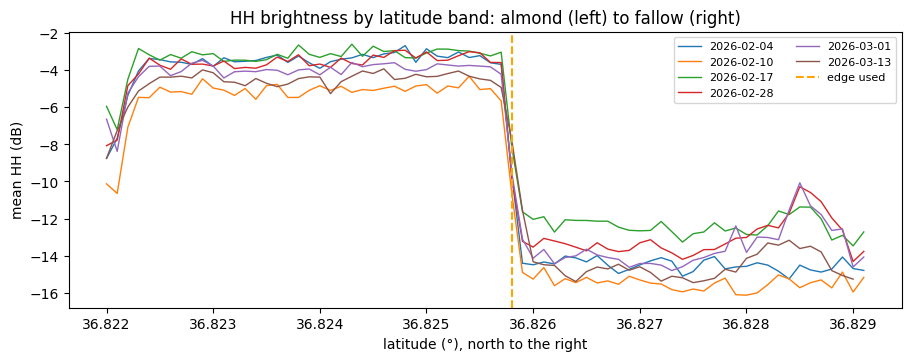

In [7]:
fig, ax = plt.subplots(figsize=(9, 3.5), layout="constrained")
for date, day in pixels.groupby("Date"):
    bands = day.groupby(day["Latitude"].round(4))["HH"].agg(["mean", "size"])
    bands = bands[bands["size"] >= bands["size"].median() / 2]
    ax.plot(bands.index, 10 * np.log10(bands["mean"]), label=date, lw=1)
ax.axvline(EDGE, color="orange", ls="--", label="edge used")
ax.set_xlabel("latitude (°), north to the right")
ax.ticklabel_format(axis="x", useOffset=False)
ax.set_ylabel("mean HH (dB)")
ax.set_title("HH brightness by latitude band: almond (left) to fallow (right)")
ax.legend(fontsize=8, ncol=2)
plt.savefig(os.path.join(PROCESSED_FOLDER, "Figure_Edge_Profile.png"), dpi=130)
plt.show()

## Alignment check 3: overlay

Radar on each date with NASA's grid (blue), the Config centres (red) and the crop edge (orange).

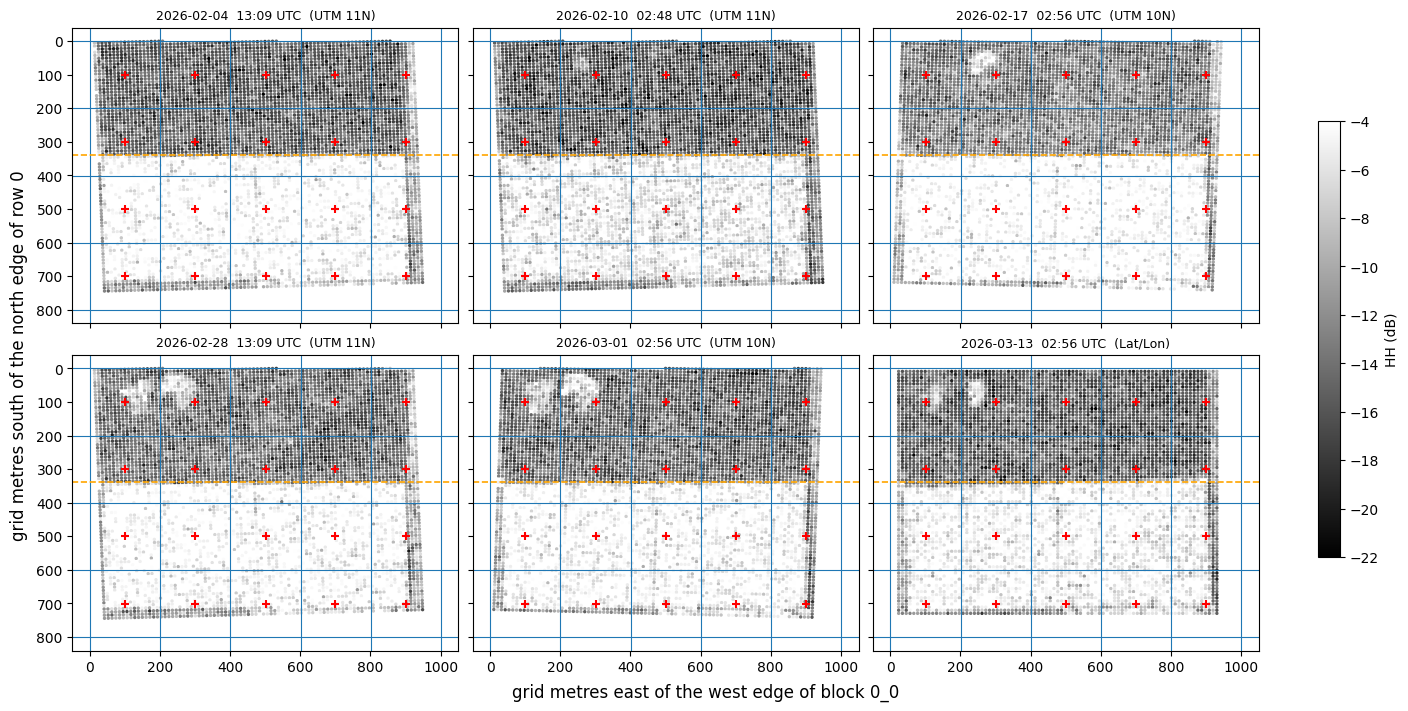

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharex=True, sharey=True, layout="constrained")
for ax, date in zip(axes.flat, dates):
    day = pixels[pixels["Date"] == date]
    dots = ax.scatter(day["East_m"], day["South_m"], c=10 * np.log10(day["HH"]), s=2, cmap="gray", vmin=-22, vmax=-4)
    for k in range(N_COLS + 1):
        ax.axvline(k * CELL_SIZE, color="tab:blue", lw=0.8)
    for k in range(N_ROWS + 1):
        ax.axhline(k * CELL_SIZE, color="tab:blue", lw=0.8)
    ax.scatter((config_cols - FIRST_COL) * CELL_SIZE, (config_rows - FIRST_ROW) * CELL_SIZE, marker="+", color="red", s=40)
    ax.axhline(EDGE_SOUTH_M, color="orange", ls="--", lw=1.2)
    ax.set_title(f"{date}  {day['Pass'].iloc[0]}  ({day['Coordinates'].iloc[0]})", fontsize=9)
axes[0, 0].invert_yaxis()
fig.supxlabel("grid metres east of the west edge of block 0_0")
fig.supylabel("grid metres south of the north edge of row 0")
fig.colorbar(dots, ax=axes, label="HH (dB)", shrink=0.7)
plt.savefig(os.path.join(PROCESSED_FOLDER, "Figure_Alignment_Check.png"), dpi=130)
plt.show()

## Alignment check 4: image matching

Each date's HH image goes on a common 10 m grid and slides against Feb 4, up to 50 m in each direction. The crop edge and other
field features line up only at the right shift, so the best match should sit at zero. A parabola through the three scores around
the peak gives the offset to within a fraction of a pixel.

In [9]:
def hh_image(day):
    cells = day.assign(east=(day["East_m"] // 10).astype(int), south=(day["South_m"] // 10).astype(int))
    return 10 * np.log10(cells.groupby(["south", "east"])["HH"].mean().unstack())


def overlap(a, b):
    both = pd.concat([a.stack(), b.stack()], axis=1).dropna()
    return both.corr().iloc[0, 1]


def fine_offset(minus, zero, plus):
    return 5 * (minus - plus) / (minus - 2 * zero + plus)      # metres; peak of a parabola through 3 scores 10 m apart


reference = hh_image(pixels[pixels["Date"] == dates[0]])
shifts = [(e, s) for e in range(-5, 6) for s in range(-5, 6)]     # steps of 10 m, up to 50 m
match = []
for date in dates:
    image = hh_image(pixels[pixels["Date"] == date]).reindex_like(reference)
    score = {(e, s): overlap(reference, image.shift(s, axis=0).shift(e, axis=1)) for e, s in shifts}
    best_e, best_s = max(score, key=score.get)
    one_pixel = np.mean([score[(1, 0)], score[(-1, 0)], score[(0, 1)], score[(0, -1)]])
    match.append([date, pixels.loc[pixels["Date"] == date, "Coordinates"].iloc[0], score[(0, 0)], one_pixel,
                  best_e * 10, best_s * 10,
                  fine_offset(score[(-1, 0)], score[(0, 0)], score[(1, 0)]),
                  fine_offset(score[(0, -1)], score[(0, 0)], score[(0, 1)])])
match = pd.DataFrame(match, columns=["Date", "Coordinates", "Match at 0 m", "Match at 10 m", "Best shift east (m)",
                                     "Best shift south (m)", "Fine offset east (m)", "Fine offset south (m)"])
match.round(3)

,Date,Coordinates,Match at 0 m,Match at 10 m,Best shift east (m),Best shift south (m),Fine offset east (m),Fine offset south (m)
0,2026-02-04,UTM 11N,1.000,0.897,0,0,-0.000,-0.000
1,2026-02-10,UTM 11N,0.872,0.860,0,0,-2.190,-0.183
2,2026-02-17,UTM 10N,0.866,0.850,0,0,-0.192,0.737
3,2026-02-28,UTM 11N,0.901,0.854,0,0,-0.339,-0.456
4,2026-03-01,UTM 10N,0.861,0.846,0,0,0.645,0.085
5,2026-03-13,Lat/Lon,0.861,0.853,0,0,-2.682,-4.193


## Alignment check 5: how much would a small error matter?

Check 4 compares dates with each other, so it cannot see an error shared by all six (for example, if the coordinates marked
pixel corners instead of centres). Shifting every pixel by half a pixel (5 m) and one pixel (10 m) shows the effect on the
four Clean fallow blocks used for the model.

In [10]:
def block_hh_db(east=0, south=0):
    col = np.floor((pixels["East_m"] + east) / CELL_SIZE).astype(int).rename("Col")
    row = np.floor((pixels["South_m"] + south) / CELL_SIZE).astype(int).rename("Row")
    return 10 * np.log10(pixels.groupby([pixels["Date"], row, col])["HH"].mean()), (col != pixels["Col"]) | (row != pixels["Row"])


base, _ = block_hh_db()
clean_fallow = [(0, c) for c in range(4)]
rows = []
for metres in [5, 10]:
    for east, south in [(metres, 0), (0, metres)]:
        shifted, moved = block_hh_db(east, south)
        change = (shifted - base).dropna().droplevel("Date")
        change = change[change.index.isin(clean_fallow)].abs()
        rows.append([f"{east} m east, {south} m south", moved.mean(), change.median(), change.max()])
pd.DataFrame(rows, columns=["Shift", "Pixels that change block", "Median HH change (dB)", "Largest HH change (dB)"]).round(3)

,Shift,Pixels that change block,Median HH change (dB),Largest HH change (dB)
0,"5 m east, 0 m south",0.022,0.032,0.079
1,"0 m east, 5 m south",0.021,0.017,0.100
2,"10 m east, 0 m south",0.044,0.036,0.137
3,"0 m east, 10 m south",0.043,0.035,0.137


## 4. Join SME2

Matched by **UTC date** and block ID. Four of the six radar passes are evening passes (`02:48–02:56 UTC`), which fall on the
previous evening (`18:48–19:56 PST`) in California local time. Matching by UTC date pairs all 6 radar passes with SME2 without
losing a single pixel. Matching by local date would fail on `2026-02-10 02:48 UTC` (local date `2026-02-09` does not exist in
SME2) and would collide `2026-03-01 02:56 UTC` (local `2026-02-28 18:56 PST`) with the `2026-02-28 13:09 UTC` morning pass.
Blocks without a valid SME2 value (0 to 1) are dropped.

In [11]:
sme2 = pd.read_excel(SME2_FILE)
sme2["Date"] = pd.to_datetime(sme2["date"].astype(str), format="%Y%m%d").dt.strftime("%Y-%m-%d")
sme2_dates = set(sme2["Date"].unique())
sme2 = sme2.drop(columns="date").melt(id_vars="Date", var_name="Block_ID", value_name="SME2")
sme2["Block_ID"] = "B" + sme2["Block_ID"]
sme2 = sme2[(sme2["SME2"] >= 0) & (sme2["SME2"] <= 1)]

before = len(pixels)
pixels = pixels.merge(sme2, on=["Date", "Block_ID"])
print("Pixels before the join:", before, " after:", len(pixels), " dropped for missing SME2:", before - len(pixels))
print("All 6 radar UTC dates present in SME2:", all(d in sme2_dates for d in dates),
      "| Local date 2026-02-09 present in SME2:", "2026-02-09" in sme2_dates)

Pixels before the join: 40556  after: 40556  dropped for missing SME2: 0
All 6 radar UTC dates present in SME2: True | Local date 2026-02-09 present in SME2: False


## 5. Average to 200 m, 100 m and 50 m

Blocks, 2 × 2 pieces and 4 × 4 pieces. Features: **HH_dB** (moisture signal), **HV_dB** (vegetation and roughness) and
**HV_HH_Ratio** (canopy vs bare soil, kept in linear units because in dB it would equal `HV_dB − HH_dB`). **Block_HH_dB**
lets each piece be compared with its own block.

**Why linear power is averaged before converting to dB.** Because the logarithm is curved (Jensen's inequality), averaging
pixel dB values directly always underestimates true radar power—by **0.81 dB** on average across Clean fallow blocks and by
**3.29 dB** across Mixed blocks where bright almond pixels meet dark fallow soil. Averaging in linear power first avoids this
bias and guarantees that the pixel-weighted linear power of the 100 m and 50 m pieces equals the 200 m block power exactly.

In [12]:
pixels["Almond"] = (pixels["Crop"] == "Almond").astype(int)
pixels["Block_HH_linear"] = pixels.groupby(["Date", "Block_ID"])["HH"].transform("mean")
pixels["HH_pixel_dB"] = 10 * np.log10(pixels["HH"])

def average_pixels(n):
    p = pixels.copy()
    p["Piece_ID"] = ("P" + (p["Y_in_block"] * n).astype(int).astype(str)
                     + "_" + (p["X_in_block"] * n).astype(int).astype(str))

    t = p.groupby(["Date", "Pass", "Block_ID", "Piece_ID"], as_index=False).agg(
        Latitude=("Latitude", "mean"),
        Longitude=("Longitude", "mean"),
        Pixels=("HH", "count"),
        Almond_Share=("Almond", "mean"),
        HH_linear=("HH", "mean"),
        HV_linear=("HV", "mean"),
        HH_direct_dB=("HH_pixel_dB", "mean"),
        Block_HH_linear=("Block_HH_linear", "first"),
        SME2=("SME2", "first"))

    t["Crop"] = np.where(t["Almond_Share"] >= 0.5, "Almond", "Fallow")
    t["HH_dB"] = 10 * np.log10(t["HH_linear"])
    t["HV_dB"] = 10 * np.log10(t["HV_linear"])
    t["HV_HH_Ratio"] = t["HV_linear"] / t["HH_linear"]
    t["Block_HH_dB"] = 10 * np.log10(t["Block_HH_linear"])
    t["dB_Bias_Avoided"] = t["HH_dB"] - t["HH_direct_dB"]
    return t.sort_values(["Date", "Block_ID", "Piece_ID"]).reset_index(drop=True)

blocks = average_pixels(1)
pieces_100 = average_pixels(2)
pieces_50 = average_pixels(4)

for label, piece_df in [("100 m", pieces_100), ("50 m", pieces_50)]:
    weighted = (piece_df["HH_linear"] * piece_df["Pixels"]).groupby([piece_df["Date"], piece_df["Block_ID"]]).sum()
    total_px = piece_df.groupby(["Date", "Block_ID"])["Pixels"].sum()
    block_ref = blocks.set_index(["Date", "Block_ID"])
    max_err = (weighted / total_px - block_ref["HH_linear"]).abs().max()
    px_diff = (total_px - block_ref["Pixels"]).abs().max()
    print(f"{label:5s} -> 200 m conservation: total pixels = {total_px.sum():,}, max pixel diff = {px_diff}, max linear HH diff = {max_err:.1e}")

100 m -> 200 m conservation: total pixels = 40,556, max pixel diff = 0, max linear HH diff = 2.8e-17
50 m  -> 200 m conservation: total pixels = 40,556, max pixel diff = 0, max linear HH diff = 0.0e+00


## 6. Block type: partial cover and the crop boundary

Two things change radar brightness without any change in soil moisture, so blocks with either one are kept out of training:

- **Partial cover (Edge).** The image ends partway through the east column and the bottom row. The radar average then
  describes only part of the cell, while SME2 describes the whole cell. Blocks under 80% cover (320 pixels) are Edge.
  At 50 m resolution, all 210 empty sub-cells (`1,920 − 1,710`) occur in the outer strip of these Edge blocks where the radar
  swath ends; every Clean and Mixed block has all 4 of its 100 m pieces and all 16 of its 50 m pieces populated.
- **Almond trees (Mixed).** The edge found in section 3 runs through row 1, so those blocks are part orchard. Tree canopy
  scatters far more energy than bare soil. A block with any almond pixel, but not all, is Mixed.

Both labels come from radar cover and the crop edge only; SME2 plays no part, so the labels cannot favour the model.

In [13]:
blocks["Block_Type"] = "Clean"
blocks.loc[(blocks["Almond_Share"] > 0) & (blocks["Almond_Share"] < 1), "Block_Type"] = "Mixed"
blocks.loc[blocks["Pixels"] < EDGE_PIXELS, "Block_Type"] = "Edge"

block_type = blocks[["Date", "Block_ID", "Block_Type"]]
pieces_100 = pieces_100.merge(block_type, on=["Date", "Block_ID"])
pieces_50 = pieces_50.merge(block_type, on=["Date", "Block_ID"])
print("200 m blocks:", len(blocks), "  100 m pieces:", len(pieces_100), "  50 m pieces:", len(pieces_50))

FULL_BLOCK = (CELL_SIZE / 10) ** 2       # about 400 pixels of 10 m
block_summary = blocks.groupby("Block_ID").agg(
    Block_Type=("Block_Type", "first"), Crop=("Crop", "first"),
    Coverage_min=("Pixels", "min"), Coverage_max=("Pixels", "max"),
    Almond_Share=("Almond_Share", "mean"))
block_summary["Coverage_min"] = (block_summary["Coverage_min"] / FULL_BLOCK).round(2)
block_summary["Coverage_max"] = (block_summary["Coverage_max"] / FULL_BLOCK).round(2)
block_summary["Almond_Share"] = block_summary["Almond_Share"].round(2)
block_summary.T

200 m blocks: 120   100 m pieces: 480   50 m pieces: 1710


Block_ID,B0_0,B0_1,B0_2,B0_3,B0_4,B1_0,B1_1,B1_2,B1_3,B1_4,B2_0,B2_1,B2_2,B2_3,B2_4,B3_0,B3_1,B3_2,B3_3,B3_4
Block_Type,Clean,Clean,Clean,Clean,Edge,Mixed,Mixed,Mixed,Mixed,Edge,Clean,Clean,Clean,Clean,Edge,Edge,Edge,Edge,Edge,Edge
Crop,Fallow,Fallow,Fallow,Fallow,Fallow,Fallow,Fallow,Fallow,Fallow,Fallow,Almond,Almond,Almond,Almond,Almond,Almond,Almond,Almond,Almond,Almond
Coverage_min,0.85,0.94,0.99,0.94,0.64,0.91,0.97,1.02,0.97,0.7,0.86,0.99,0.98,0.99,0.64,0.59,0.63,0.66,0.63,0.45
Coverage_max,0.96,1.02,1.0,1.01,0.72,0.93,0.99,1.04,0.99,0.71,0.93,1.02,1.04,1.03,0.72,0.61,0.7,0.68,0.69,0.47
Almond_Share,0.0,0.0,0.0,0.0,0.0,0.31,0.3,0.31,0.3,0.32,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


**Which records are used.** 20 blocks × 6 dates = 120 block-date records.

| Group | Blocks | Records | Used for |
|---|---|---|---|
| Clean (full cover, one crop) | B0_0 to B0_3 (fallow), B2_0 to B2_3 (almond) | 48 | Not used as a group; Clean is a quality label, not a crop |
| **Clean fallow** | B0_0 to B0_3 | **24** | Training and testing β, and the 100 m / 50 m maps |
| Mostly fallow (Clean + Mixed + Edge) | rows 0 and 1, under 50% almond | 60 | Stress test only: how much almond and partial cover hurt |
| Almond (rows 2 and 3) | B2_0 to B3_4 | 60 | Not used: one β cannot cover bare soil and tree canopy, and 4 clean almond blocks are too few for a second β |

So the 48 and the 60 are two different cuts of the same 120 records: the model notebook trains on the 24 records in both.

In [14]:
pd.crosstab(blocks["Block_Type"], blocks["Crop"], margins=True)

Crop,Almond,Fallow,All
Block_Type,,,
Clean,24,24,48
Edge,36,12,48
Mixed,0,24,24
All,60,60,120


**Why Mixed and Edge stay out of training.** On the same date, compared with the Clean fallow blocks:

In [15]:
fallow_rows = blocks[blocks["Crop"] == "Fallow"]
clean_mean = fallow_rows[fallow_rows["Block_Type"] == "Clean"].groupby("Date")[["HH_dB", "SME2"]].mean()
gap = fallow_rows.set_index("Date")[["HH_dB", "SME2"]] - clean_mean
gap["Block_Type"] = fallow_rows["Block_Type"].values
gap.groupby("Block_Type")[["HH_dB", "SME2"]].mean().round(3).rename(
    columns={"HH_dB": "Brighter by (dB)", "SME2": "SME2 wetter by (m³/m³)"})

,Brighter by (dB),SME2 wetter by (m³/m³)
Block_Type,,
Clean,0.000,0.000
Edge,3.046,0.001
Mixed,5.778,0.020


Mixed blocks are about 6 dB brighter while SME2 is only about 0.02 m³/m³ wetter. With β ≈ 0.017 m³/m³ per dB, that
brightness would read as about 0.10 m³/m³ of extra moisture, five times what SME2 shows. Edge blocks average 3 dB brighter, mostly from B1_4, which is also part almond (`+5.27 dB` on B1_4 vs `+0.82 dB` on pure-fallow B0_4). The maps use only B0_0 to B0_3,
which sit about 150 m (on the ground) north of the crop edge, so no 100 m or 50 m piece touches almond.

## 7. Validate the prepared dataset

Before saving, the table and three-panel chart below summarize the physical and numerical accuracy of the prepared dataset:

1. **Physical regime separation across block groups:** Clean fallow (`B0_0–B0_3`), Mixed fallow (`B1_0–B1_3`), pure-fallow Edge (`B0_4`), part-almond Edge (`B1_4`), and Almond (`Rows 2–3`) separate cleanly in radar brightness. Because backscatter averages linearly in power, the ~31% almond share in Mixed fallow contributes ~70% of linear power, explaining its `+5.78 dB` jump over Clean fallow on the same date (`+10.30 dB` for 100% Almond) despite minimal SME2 difference.
2. **Radar-to-moisture consistency on Clean fallow:** Across the 24 Clean fallow records, `HH_dB` correlates strongly with NASA's `SME2` ($r = 0.67$ overall; $r = 0.71$ across daily field means). Removing day-wide weather and pass effects (block minus field on the same date) strengthens the spatial correlation to $r = 0.77$ overall and $r = 1.00$ on the most varied date (Mar 1), whereas pooling all 120 blocks without filtering collapses the correlation to $r = 0.03$.
3. **Exact multi-scale conservation (`200 m → 100 m → 50 m`):** On the four Clean fallow blocks, all 24 blocks (`200 m`), 96 pieces (`100 m`), and 384 pieces (`50 m`) have 100% sub-cell presence, zero missing values, and conserve pixel counts (`9,233` pixels) and pixel-weighted linear HH/HV power to machine precision (`≤ 1.1e-16`), while expanding the captured spatial detail from `±1.57 dB` at 200 m to `±1.94 dB` at 50 m.

In [16]:
clean_daily = blocks[blocks["Block_ID"].isin(["B0_0", "B0_1", "B0_2", "B0_3"])].groupby("Date")[["HH_dB", "SME2"]].mean()
val = blocks.merge(clean_daily, on="Date", suffixes=("", "_clean_mean"))
val["dHH_vs_Clean"] = val["HH_dB"] - val["HH_dB_clean_mean"]
val["dSME2_vs_Clean"] = val["SME2"] - val["SME2_clean_mean"]

group_order = [
    ("Clean fallow (B0_0..B0_3)", val["Block_ID"].isin(["B0_0", "B0_1", "B0_2", "B0_3"])),
    ("Edge fallow, pure (B0_4)", val["Block_ID"] == "B0_4"),
    ("Mixed fallow (B1_0..B1_3)", val["Block_ID"].isin(["B1_0", "B1_1", "B1_2", "B1_3"])),
    ("Edge fallow, almond (B1_4)", val["Block_ID"] == "B1_4"),
    ("Clean almond (B2_0..B2_3)", val["Block_ID"].isin(["B2_0", "B2_1", "B2_2", "B2_3"])),
    ("Edge almond (B2_4, B3_0..B3_4)", val["Block_ID"].isin(["B2_4", "B3_0", "B3_1", "B3_2", "B3_3", "B3_4"])),
]

val_rows = []
for name, mask in group_order:
    sub = val[mask]
    val_rows.append({
        "Block group": name,
        "Records": len(sub),
        "Pixels (min-max)": f"{sub['Pixels'].min()}-{sub['Pixels'].max()}",
        "Almond share": sub["Almond_Share"].mean().round(2),
        "Mean HH (dB)": sub["HH_dB"].mean().round(2),
        "Mean HV (dB)": sub["HV_dB"].mean().round(2),
        "dB bias avoided": sub["dB_Bias_Avoided"].mean().round(2),
        "Mean SME2": sub["SME2"].mean().round(3),
        "Same-day dHH (dB)": sub["dHH_vs_Clean"].mean().round(2),
        "Same-day dSME2": sub["dSME2_vs_Clean"].mean().round(3),
    })
pd.DataFrame(val_rows).set_index("Block group")

,Records,Pixels (min-max),Almond share,Mean HH (dB),Mean HV (dB),dB bias avoided,Mean SME2,Same-day dHH (dB),Same-day dSME2
Block group,,,,,,,,,
Clean fallow (B0_0..B0_3),24,342-407,0.00,-14.02,-19.90,0.81,0.225,0.00,0.000
"Edge fallow, pure (B0_4)",6,258-289,0.00,-13.19,-19.83,1.27,0.222,0.82,-0.003
Mixed fallow (B1_0..B1_3),24,363-418,0.30,-8.24,-14.52,3.42,0.245,5.78,0.020
"Edge fallow, almond (B1_4)",6,281-286,0.32,-8.75,-14.88,2.81,0.230,5.27,0.005
Clean almond (B2_0..B2_3),24,344-418,1.00,-3.72,-9.97,0.53,0.225,10.30,-0.000
"Edge almond (B2_4, B3_0..B3_4)",36,182-288,1.00,-4.67,-10.91,1.09,0.207,9.35,-0.018


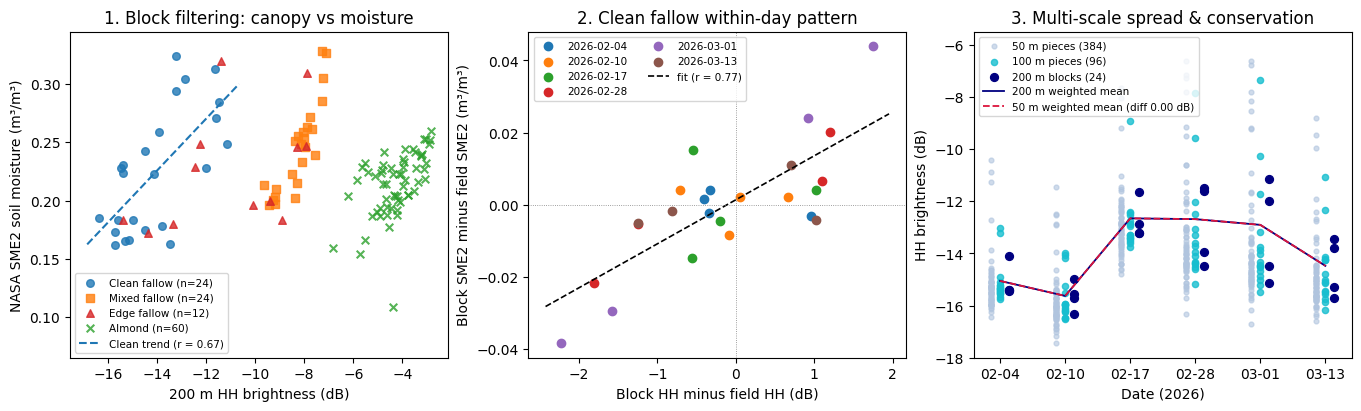

In [17]:
clean_blocks = ["B0_0", "B0_1", "B0_2", "B0_3"]
cf_200 = blocks[blocks["Block_ID"].isin(clean_blocks)].copy()
cf_100 = pieces_100[pieces_100["Block_ID"].isin(clean_blocks)].copy()
cf_50 = pieces_50[pieces_50["Block_ID"].isin(clean_blocks)].copy()

# Same-day anomalies on Clean fallow (pixel-weighted field HH, mean field SME2)
cf_200["weighted_hh"] = cf_200["HH_linear"] * cf_200["Pixels"]
day_sums = cf_200.groupby("Date")[["weighted_hh", "Pixels"]].transform("sum")
cf_200["HH_diff"] = cf_200["HH_dB"] - 10 * np.log10(day_sums["weighted_hh"] / day_sums["Pixels"])
cf_200["SM_diff"] = cf_200["SME2"] - cf_200.groupby("Date")["SME2"].transform("mean")

fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.0), layout="constrained")

# Panel 1: 200 m HH_dB vs SME2 by block group (shows why filtering to Clean fallow is essential)
groups_plot = [
    ("Clean fallow (n=24)", blocks["Block_ID"].isin(clean_blocks), "tab:blue", "o"),
    ("Mixed fallow (n=24)", blocks["Block_Type"] == "Mixed", "tab:orange", "s"),
    ("Edge fallow (n=12)", (blocks["Block_Type"] == "Edge") & (blocks["Crop"] == "Fallow"), "tab:red", "^"),
    ("Almond (n=60)", blocks["Crop"] == "Almond", "tab:green", "x"),
]
for label, mask, color, marker in groups_plot:
    sub = blocks[mask]
    axes[0].scatter(sub["HH_dB"], sub["SME2"], label=label, color=color, marker=marker, s=30, alpha=0.8)

slope, intercept = np.polyfit(cf_200["HH_dB"], cf_200["SME2"], 1)
x_line = np.linspace(cf_200["HH_dB"].min() - 0.5, cf_200["HH_dB"].max() + 0.5, 50)
r_abs = cf_200["HH_dB"].corr(cf_200["SME2"])
axes[0].plot(x_line, slope * x_line + intercept, color="tab:blue", ls="--", lw=1.5, label=f"Clean trend (r = {r_abs:.2f})")
axes[0].set_ylim(0.065, 0.345)
axes[0].set_xlabel("200 m HH brightness (dB)")
axes[0].set_ylabel("NASA SME2 soil moisture (m³/m³)")
axes[0].set_title("1. Block filtering: canopy vs moisture")
axes[0].legend(fontsize=7.5, loc="lower left")

# Panel 2: Within-date spatial pattern on Clean fallow (block minus field)
for date, day in cf_200.groupby("Date"):
    axes[1].scatter(day["HH_diff"], day["SM_diff"], label=date, s=36)
anom_slope, anom_int = np.polyfit(cf_200["HH_diff"], cf_200["SM_diff"], 1)
x_anom = np.linspace(cf_200["HH_diff"].min() - 0.2, cf_200["HH_diff"].max() + 0.2, 50)
r_anom = cf_200["HH_diff"].corr(cf_200["SM_diff"])
axes[1].plot(x_anom, anom_slope * x_anom + anom_int, color="black", ls="--", lw=1.2, label=f"fit (r = {r_anom:.2f})")
axes[1].axhline(0, color="grey", lw=0.6, ls=":")
axes[1].axvline(0, color="grey", lw=0.6, ls=":")
axes[1].set_xlabel("Block HH minus field HH (dB)")
axes[1].set_ylabel("Block SME2 minus field SME2 (m³/m³)")
axes[1].set_title("2. Clean fallow within-day pattern")
axes[1].legend(fontsize=7.5, ncol=2, loc="upper left")

# Panel 3: Multi-scale consistency & detail across the 6 dates (200 m, 100 m, 50 m on Clean fallow)
x_idx = np.arange(len(dates))
for i, d in enumerate(dates):
    d50 = cf_50[cf_50["Date"] == d]["HH_dB"]
    d100 = cf_100[cf_100["Date"] == d]["HH_dB"]
    d200 = cf_200[cf_200["Date"] == d]["HH_dB"]
    axes[2].scatter(np.full(len(d50), i) - 0.14, d50, color="lightsteelblue", s=12, alpha=0.6, label="50 m pieces (384)" if i == 0 else "")
    axes[2].scatter(np.full(len(d100), i), d100, color="tab:cyan", s=20, alpha=0.8, label="100 m pieces (96)" if i == 0 else "")
    axes[2].scatter(np.full(len(d200), i) + 0.14, d200, color="navy", s=32, label="200 m blocks (24)" if i == 0 else "")

# Compare pixel-weighted 200 m field mean vs 50 m pixel-weighted field mean on each date
mean_200 = [10 * np.log10(np.average(cf_200[cf_200["Date"] == d]["HH_linear"], weights=cf_200[cf_200["Date"] == d]["Pixels"])) for d in dates]
mean_50 = [10 * np.log10(np.average(cf_50[cf_50["Date"] == d]["HH_linear"], weights=cf_50[cf_50["Date"] == d]["Pixels"])) for d in dates]
axes[2].plot(x_idx, mean_200, color="navy", lw=1.3, label="200 m weighted mean")
axes[2].plot(x_idx, mean_50, color="crimson", ls="--", lw=1.3, label="50 m weighted mean (diff 0.00 dB)")
axes[2].set_ylim(-18.0, -5.5)
axes[2].set_xticks(x_idx, [d[5:] for d in dates])
axes[2].set_xlabel("Date (2026)")
axes[2].set_ylabel("HH brightness (dB)")
axes[2].set_title("3. Multi-scale spread & conservation")
axes[2].legend(fontsize=7.5, loc="upper left")

plt.savefig(os.path.join(PROCESSED_FOLDER, "Figure_Data_Prep_Validation.png"), dpi=130)
plt.show()

## 8. Save

In [18]:
block_cols = ["Date", "Pass", "Block_ID", "Latitude", "Longitude", "Pixels", "Crop", "Block_Type",
              "HH_linear", "HV_linear", "HH_dB", "HV_dB", "HV_HH_Ratio", "SME2"]
piece_cols = ["Date", "Pass", "Block_ID", "Piece_ID", "Latitude", "Longitude", "Pixels", "Crop", "Block_Type",
              "HH_linear", "HV_linear", "HH_dB", "HV_dB", "HV_HH_Ratio", "Block_HH_dB", "SME2"]

with pd.ExcelWriter(OUTPUT_FILE) as writer:
    blocks[block_cols].to_excel(writer, sheet_name="Blocks 200m", index=False)
    pieces_100[piece_cols].rename(columns={"SME2": "Block_SME2"}).to_excel(writer, sheet_name="Pieces 100m", index=False)
    pieces_50[piece_cols].rename(columns={"SME2": "Block_SME2"}).to_excel(writer, sheet_name="Pieces 50m", index=False)
print("Saved", OUTPUT_FILE)

Saved ../Processed Data/Downscaling_Dataset.xlsx
